# Comparing PCA and t-SNE for Handwritten Digit Data: Dimensionality Reduction and K-Means Clustering

## 1. Introduction

### 1.1 Background

Machine learning datasets often contain many features, making them difficult to visualize, analyze, and cluster directly. Dimensionality reduction addresses this challenge by transforming high-dimensional data into a lower-dimensional representation while attempting to preserve important information or structure. Clustering, in contrast, aims to group similar data points without relying on predefined class labels.

Principal Component Analysis (PCA) and t-distributed Stochastic Neighbor Embedding (t-SNE) are two widely used dimensionality reduction techniques. PCA is a linear method that identifies directions of maximum variance in the data, whereas t-SNE is a nonlinear method designed to preserve local neighborhood relationships and is commonly used for visualization.

K-Means is an unsupervised clustering algorithm that partitions data into a specified number of clusters by minimizing the within-cluster sum of squared distances to cluster centroids. Its results depend partly on the selected number of clusters, \(K\). The Elbow method and Silhouette score can help investigate a suitable value of \(K\) before performing clustering.

Domain Knowledge is another important way to select the number of clusters \(K\).

Combining dimensionality reduction with clustering makes it possible to investigate not only how the data can be visualized in fewer dimensions, but also how the resulting representations affect the structure and quality of the clusters identified by K-Means.

### 1.2 Dataset

The original MNIST dataset contains 70,000 grayscale images of handwritten digits from 0 to 9. Each image has 28 × 28 pixels and can therefore be represented as a vector of 784 pixel-intensity features.

This project uses the **Digits dataset provided by scikit-learn**, a smaller dataset of handwritten digit images. It contains 1,797 samples, each represented by an 8 × 8 image and 64 pixel-intensity features. The dataset covers all ten digit classes, from 0 to 9, with pixel intensities ranging from 0 to 16.

The dataset includes known digit labels. These labels will be used to visualize the digit classes and evaluate clustering results, but they will not be provided to PCA, t-SNE, or K-Means during their unsupervised fitting procedures.

### 1.3 Objectives and Research Questions

The main objective is to investigate how dimensionality reduction affects the visualization and clustering of handwritten digit data. The project compares K-Means clustering on the original feature space with clustering on representations produced by PCA and t-SNE.

The project investigates the following research questions:

1. How effectively do PCA and t-SNE reveal patterns and separation between digit classes in two-dimensional visualizations?
2. What number of clusters is suggested by the Elbow method and Silhouette score when applied to the original feature space?
3. How well does K-Means identify meaningful groups in the original 64-dimensional feature space?
4. How does clustering performance change when K-Means is applied to PCA-reduced features compared with the original features?
5. How does clustering performance change when K-Means is applied to t-SNE embeddings, and how should the limitations of this approach affect the interpretation of the results?
6. How much variance does PCA preserve, how well do the reduced representations preserve local neighborhoods, and how do the methods compare in computational runtime?
7. How do different t-SNE perplexity values affect the resulting visualization, neighborhood preservation, and clustering outcomes?

### 1.4 Methodology and Evaluation Approach

The analysis will begin with exploratory data analysis to examine the dataset's dimensions, pixel intensities, class distribution, and example digit images.

Next, the Elbow method and Silhouette score will be used to investigate suitable values of \(K\) for K-Means clustering. The selected value or values will be justified based on the observed results rather than assumed in advance. In case Elbow and Silhouette do not give correct \(K\) value, the Domain knowlege will be used (I am testing the accuracy of Elbow and Silhouette as well) K-Means will then be applied to the original 64-dimensional feature space to establish a baseline.

PCA and t-SNE will subsequently be applied to the original features to generate lower-dimensional representations. PCA will be evaluated using explained variance, and the effects of different t-SNE perplexity values will be investigated. K-Means will then be applied to the PCA-reduced features and the t-SNE embeddings to examine how the representations influence clustering outcomes.

The evaluation will combine visual inspection with quantitative metrics. Cluster quality will be evaluated using ARI.



In [67]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score, silhouette_score


### EDA (Exploratory Data Analysis)

In [68]:
digits = load_digits()
X = digits.data
y = digits.target
images = digits.images

print(f"Number of samples: {X.shape[0]}")
print(f"Number of features per sample: {X.shape[1]}")
print(f"Image dimensions: {images.shape[1]} x {images.shape[2]} pixels")
print(f"Digit labels: {np.unique(y)}")
print(f"Pixel intensity range: {X.min()} to {X.max()}")
print(f"Feature matrix shape: {X.shape}")
print(f"Target vector shape: {y.shape}")

class_labels, class_counts = np.unique(y, return_counts=True)
print("\nSamples per digit:")
for label, count in zip(class_labels, class_counts):
    print(f"  {label}: {count}")

Number of samples: 1797
Number of features per sample: 64
Image dimensions: 8 x 8 pixels
Digit labels: [0 1 2 3 4 5 6 7 8 9]
Pixel intensity range: 0.0 to 16.0
Feature matrix shape: (1797, 64)
Target vector shape: (1797,)

Samples per digit:
  0: 178
  1: 182
  2: 177
  3: 183
  4: 181
  5: 182
  6: 181
  7: 179
  8: 174
  9: 180


[[ 0.  0.  5. 13.  9.  1.  0.  0.]
 [ 0.  0. 13. 15. 10. 15.  5.  0.]
 [ 0.  3. 15.  2.  0. 11.  8.  0.]
 [ 0.  4. 12.  0.  0.  8.  8.  0.]
 [ 0.  5.  8.  0.  0.  9.  8.  0.]
 [ 0.  4. 11.  0.  1. 12.  7.  0.]
 [ 0.  2. 14.  5. 10. 12.  0.  0.]
 [ 0.  0.  6. 13. 10.  0.  0.  0.]]


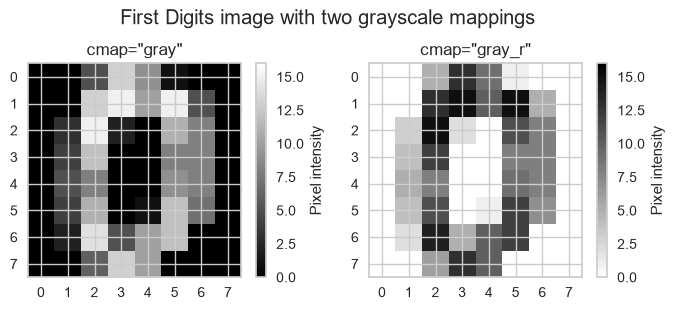

In [69]:
# Display the first image with gray and gray_r colormaps.
print(X[0].reshape(8, 8))

first_image = X[0].reshape(8, 8)
fig, axes = plt.subplots(1, 2, figsize=(7, 3))

for ax, cmap in zip(axes, ("gray", "gray_r")):
    image_plot = ax.imshow(first_image, cmap=cmap, vmin=0, vmax=16)
    ax.set_title(f'cmap="{cmap}"')
    ax.set_xticks(range(8))
    ax.set_yticks(range(8))
    fig.colorbar(image_plot, ax=ax, label="Pixel intensity")

fig.suptitle("First Digits image with two grayscale mappings")
fig.tight_layout()
plt.show()

In [5]:
# Count missing (NaN) values in the features and target labels.
feature_null_count = np.isnan(X).sum()
target_null_count = np.isnan(y).sum()

print(f"Missing values in feature matrix: {feature_null_count}")
print(f"Missing values in target labels: {target_null_count}")

Missing values in feature matrix: 0
Missing values in target labels: 0


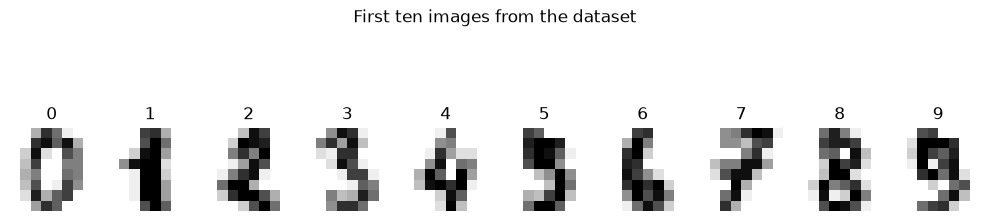

In [12]:
# Display the first ten images in the dataset with their true labels.
fig, axes = plt.subplots(1, 10, figsize=(10, 3))
fig.suptitle("First ten images from the dataset")

for i, ax in enumerate(axes):
    ax.imshow(images[i], cmap="gray_r", vmin=0, vmax=16)
    ax.set_title(f"{y[i]}")
    ax.axis("off")

fig.tight_layout()
plt.show()

#### Pixel Intensity Analysis

Examining pixel intensities helps describe how dark or bright the handwritten digits are, how pixel values are distributed, and how much of each image is background. These patterns provide context for later dimensionality reduction and clustering. 

Minimum pixel value: 0.0
Maximum pixel value: 16.0
Mean pixel value: 4.884
Median pixel value: 1.000
Standard deviation: 6.017
Proportion of zero-valued pixels: 48.93%


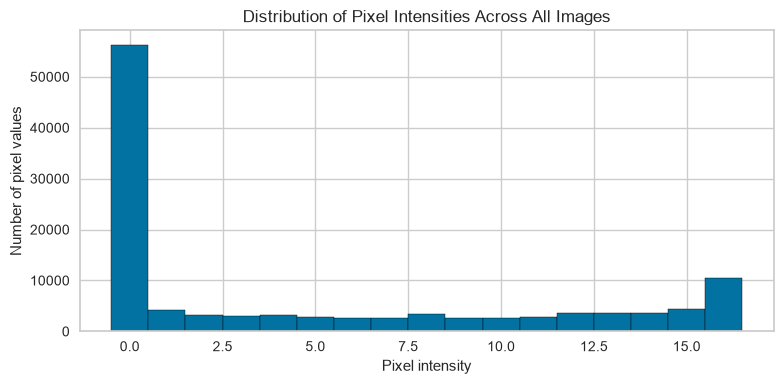

In [70]:
# Summarize all pixel values across every image and pixel position.
pixel_values = X.ravel()

print(f"Minimum pixel value: {pixel_values.min()}")
print(f"Maximum pixel value: {pixel_values.max()}")
print(f"Mean pixel value: {pixel_values.mean():.3f}")
print(f"Median pixel value: {np.median(pixel_values):.3f}")
print(f"Standard deviation: {pixel_values.std():.3f}")

# Zero-valued pixels typically represent the background in these grayscale images.
zero_proportion = np.count_nonzero(pixel_values == 0) / pixel_values.size
print(f"Proportion of zero-valued pixels: {zero_proportion:.2%}")

plt.figure(figsize=(8, 4))
plt.hist(pixel_values, bins=np.arange(pixel_values.min() - 0.5, pixel_values.max() + 1.5, 1), edgecolor="black")
plt.title("Distribution of Pixel Intensities Across All Images")
plt.xlabel("Pixel intensity")
plt.ylabel("Number of pixel values")
plt.tight_layout()
plt.show()

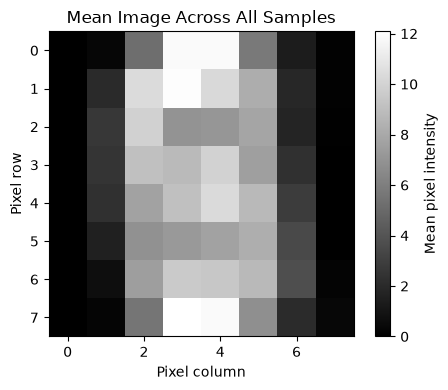

In [18]:
# Average each pixel position across all samples, then reshape to the 8 x 8 image layout.
mean_image = X.mean(axis=0).reshape(8, 8)

fig, ax = plt.subplots(figsize=(5, 4))
image_plot = ax.imshow(mean_image, cmap="gray")
ax.set_title("Mean Image Across All Samples")
ax.set_xlabel("Pixel column")
ax.set_ylabel("Pixel row")
fig.colorbar(image_plot, ax=ax, label="Mean pixel intensity")
fig.tight_layout()
plt.show()

## Selecting the Number of Clusters for K-Means on the Original Data

Use the Elbow method on the original 64-feature data matrix `X`. The distortion (within-cluster sum of squares) is plotted for K values from 1 through 15. The estimated elbow marks the point where adding more clusters begins to give diminishing reductions in distortion; treat it as a guide and inspect the curve when choosing K.

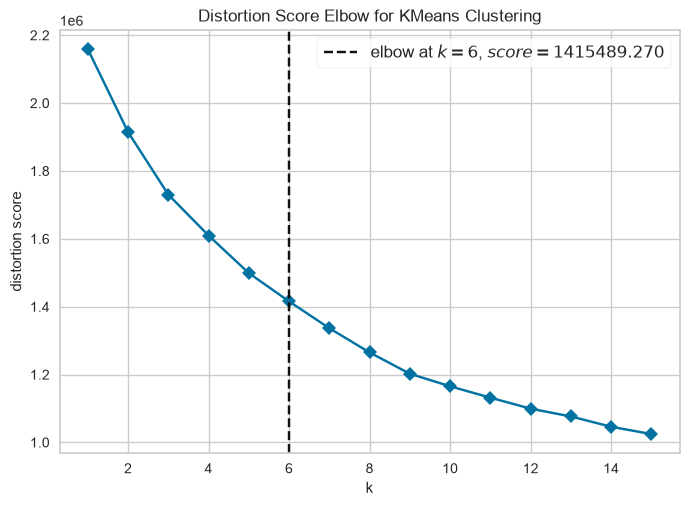

Elbow-based K estimate: 6


In [71]:
from yellowbrick.cluster import KElbowVisualizer

# Fit K-Means on the original feature matrix for K = 1, 2, ..., 15.
kmeans_model = KMeans(random_state=42, n_init=10)
elbow_visualizer = KElbowVisualizer(
    kmeans_model,
    k=(1, 16),
    metric="distortion",
    timings=False,
    force_model=True,
)
elbow_visualizer.fit(X)
elbow_visualizer.show()

# Yellowbrick estimates the elbow from the plotted distortion curve.
best_k = elbow_visualizer.elbow_value_
if best_k is None:
    print("No clear elbow was detected; choose K by visually inspecting the plotted curve.")
else:
    print(f"Elbow-based K estimate: {best_k}")

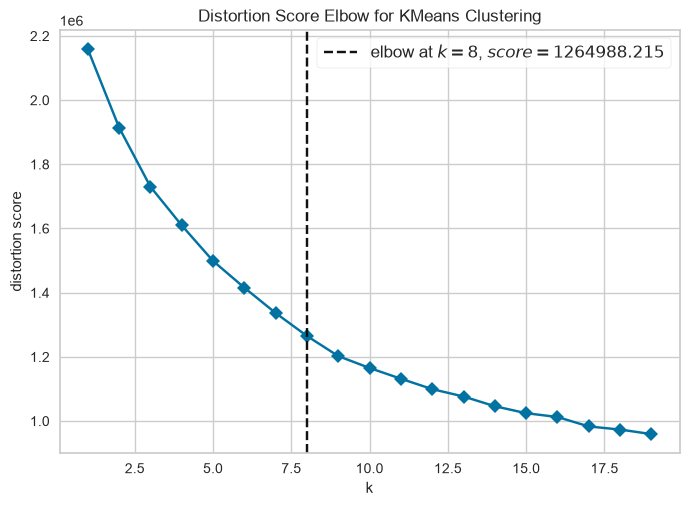

Elbow-based K estimate: 8


In [72]:
from yellowbrick.cluster import KElbowVisualizer

# Fit K-Means on the original feature matrix for K = 1, 2, ..., 15.
kmeans_model = KMeans(random_state=42, n_init=10)
elbow_visualizer = KElbowVisualizer(
    kmeans_model,
    k=(1, 20),
    metric="distortion",
    timings=False,
    force_model=True,
)
elbow_visualizer.fit(X)
elbow_visualizer.show()

# Yellowbrick estimates the elbow from the plotted distortion curve.
best_k = elbow_visualizer.elbow_value_
if best_k is None:
    print("No clear elbow was detected; choose K by visually inspecting the plotted curve.")
else:
    print(f"Elbow-based K estimate: {best_k}")

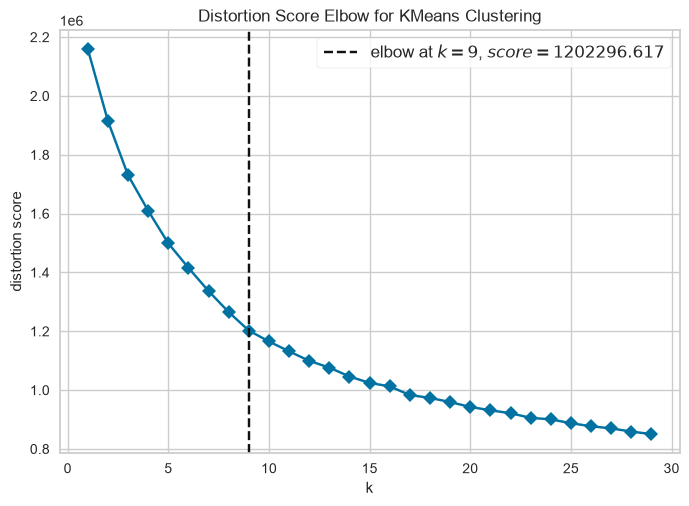

Elbow-based K estimate: 9


In [73]:
from yellowbrick.cluster import KElbowVisualizer

# Fit K-Means on the original feature matrix for K = 1, 2, ..., 15.
kmeans_model = KMeans(random_state=42, n_init=10)
elbow_visualizer = KElbowVisualizer(
    kmeans_model,
    k=(1, 30),
    metric="distortion",
    timings=False,
    force_model=True,
)
elbow_visualizer.fit(X)
elbow_visualizer.show()

# Yellowbrick estimates the elbow from the plotted distortion curve.
best_k = elbow_visualizer.elbow_value_
if best_k is None:
    print("No clear elbow was detected; choose K by visually inspecting the plotted curve.")
else:
    print(f"Elbow-based K estimate: {best_k}")

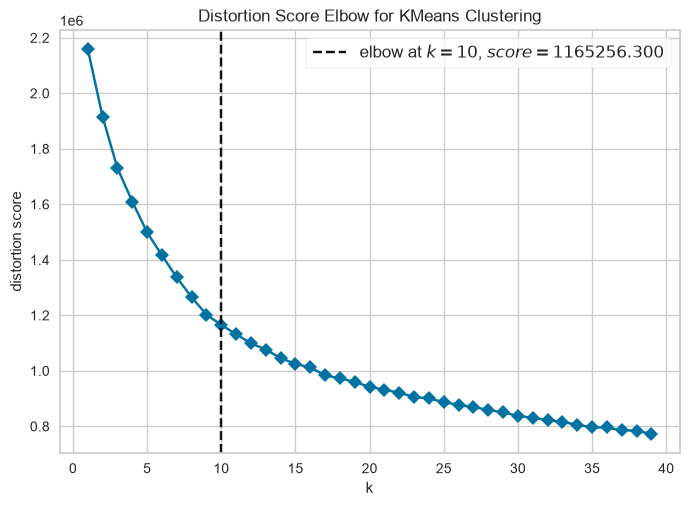

Elbow-based K estimate: 10


In [74]:
from yellowbrick.cluster import KElbowVisualizer

# Fit K-Means on the original feature matrix for K = 1, 2, ..., 15.
kmeans_model = KMeans(random_state=42, n_init=10)
elbow_visualizer = KElbowVisualizer(
    kmeans_model,
    k=(1, 40),
    metric="distortion",
    timings=False,
    force_model=True,
)
elbow_visualizer.fit(X)
elbow_visualizer.show()

# Yellowbrick estimates the elbow from the plotted distortion curve.
best_k = elbow_visualizer.elbow_value_
if best_k is None:
    print("No clear elbow was detected; choose K by visually inspecting the plotted curve.")
else:
    print(f"Elbow-based K estimate: {best_k}")

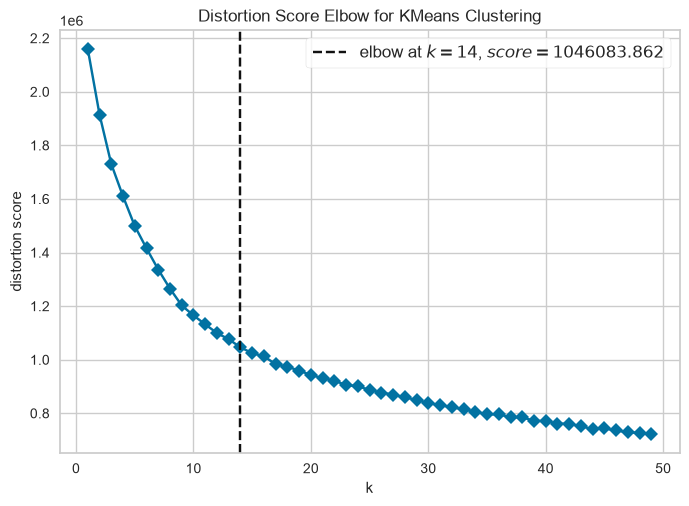

Elbow-based K estimate: 14


In [75]:
# Fit K-Means on the original feature matrix for K = 1, 2, ..., 15.
kmeans_model = KMeans(random_state=42, n_init=10)
elbow_visualizer = KElbowVisualizer(
    kmeans_model,
    k=(1, 50),
    metric="distortion",
    timings=False,
    force_model=True,
)
elbow_visualizer.fit(X)
elbow_visualizer.show()

# Yellowbrick estimates the elbow from the plotted distortion curve.
best_k = elbow_visualizer.elbow_value_
if best_k is None:
    print("No clear elbow was detected; choose K by visually inspecting the plotted curve.")
else:
    print(f"Elbow-based K estimate: {best_k}")

**Preliminary interpretation of the Elbow method**

The Elbow method did not identify a single unambiguous number of clusters. The apparent elbow changed depending on the maximum value of \(K\) included in the plot, suggesting that the inertia curve has a gradual rather than sharply defined bend. As we already know that the best \(K\) is 10, it only showed this number at k=(1, 40) while lower k showed lower optimal \(K\) and higher k value showed higher optimal value of \(K\).Therefore, the Elbow method alone does not provide sufficient evidence to select an optimal number of clusters. The Silhouette score will be examined as a complementary measure before choosing the value of \(K\) for the baseline K-means experiment.

## Silhouette Score for K-Means on the Original Data

Calculate the Silhouette score for K=2 through K=16 on the original feature matrix `X`.

The Elbow method looks for a bend where adding clusters yields diminishing reductions in within-cluster sum of squares. The Silhouette score instead measures how compact each cluster is and how separated it is from neighboring clusters; higher scores indicate better-defined clusters. Since the methods assess different properties, they can favor different values of K. Compare their suggested values and inspect the plots rather than treating either as an absolute answer.

K= 2: silhouette score = 0.1183
K= 3: silhouette score = 0.1265
K= 4: silhouette score = 0.1280
K= 5: silhouette score = 0.1362
K= 6: silhouette score = 0.1507
K= 7: silhouette score = 0.1640
K= 8: silhouette score = 0.1787
K= 9: silhouette score = 0.1891
K=10: silhouette score = 0.1824
K=11: silhouette score = 0.1833
K=12: silhouette score = 0.1829
K=13: silhouette score = 0.1869
K=14: silhouette score = 0.1840
K=15: silhouette score = 0.1864
K=16: silhouette score = 0.1687
Highest silhouette score: 0.1891 at K=9


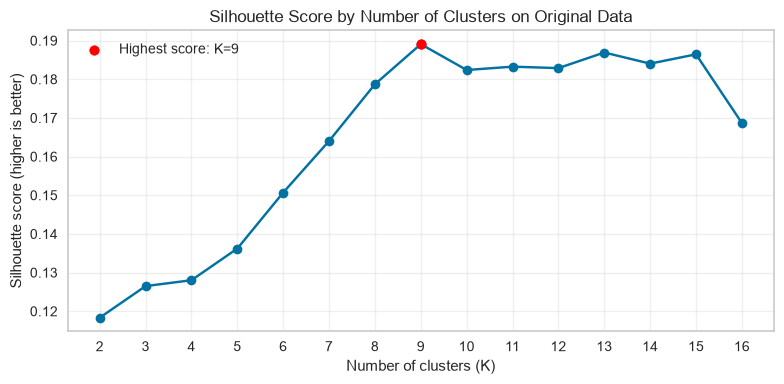

Silhouette estimate: K=9


In [45]:
# Calculate Silhouette scores for K = 2 through K = 16 on the original data.
silhouette_k_values = np.arange(2, 17)
silhouette_scores = []

for k in silhouette_k_values:
    kmeans_model = KMeans(n_clusters=int(k), random_state=42, n_init=10)
    cluster_labels = kmeans_model.fit_predict(X)
    score = silhouette_score(X, cluster_labels)
    silhouette_scores.append(score)
    print(f"K={k:2d}: silhouette score = {score:.4f}")

best_silhouette_k = int(silhouette_k_values[np.argmax(silhouette_scores)])
best_silhouette_score = float(np.max(silhouette_scores))
print(f"Highest silhouette score: {best_silhouette_score:.4f} at K={best_silhouette_k}")

plt.figure(figsize=(8, 4))
plt.plot(silhouette_k_values, silhouette_scores, marker="o")
plt.scatter(best_silhouette_k, best_silhouette_score, color="red", zorder=3, label=f"Highest score: K={best_silhouette_k}")
plt.xticks(silhouette_k_values)
plt.title("Silhouette Score by Number of Clusters on Original Data")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette score (higher is better)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print(f"Silhouette estimate: K={best_silhouette_k}")


K= 2: silhouette score = 0.1183
K= 3: silhouette score = 0.1265
K= 4: silhouette score = 0.1280
K= 5: silhouette score = 0.1362
K= 6: silhouette score = 0.1507
K= 7: silhouette score = 0.1640
K= 8: silhouette score = 0.1787
K= 9: silhouette score = 0.1891
K=10: silhouette score = 0.1824
K=11: silhouette score = 0.1833
K=12: silhouette score = 0.1829
K=13: silhouette score = 0.1869
K=14: silhouette score = 0.1840
K=15: silhouette score = 0.1864
K=16: silhouette score = 0.1687
K=17: silhouette score = 0.1774
K=18: silhouette score = 0.1728
K=19: silhouette score = 0.1684
K=20: silhouette score = 0.1723
K=21: silhouette score = 0.1703
K=22: silhouette score = 0.1695
K=23: silhouette score = 0.1676
K=24: silhouette score = 0.1625
K=25: silhouette score = 0.1427
K=26: silhouette score = 0.1650
K=27: silhouette score = 0.1434
K=28: silhouette score = 0.1467
K=29: silhouette score = 0.1620
Highest silhouette score: 0.1891 at K=9


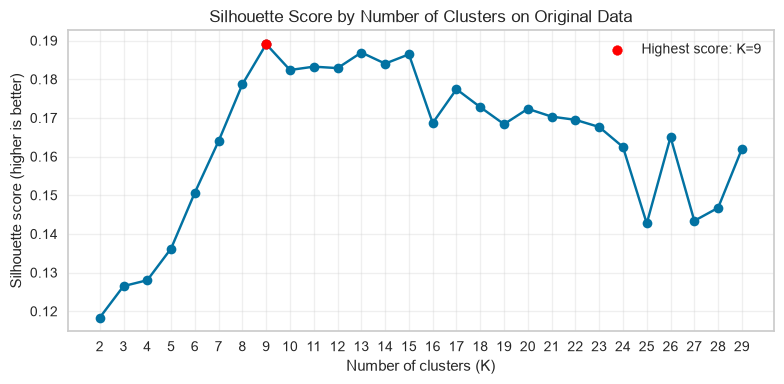

Silhouette estimate: K=9


In [44]:
# Calculate Silhouette scores for K = 2 through K = 16 on the original data.
silhouette_k_values = np.arange(2, 30)
silhouette_scores = []

for k in silhouette_k_values:
    kmeans_model = KMeans(n_clusters=int(k), random_state=42, n_init=10)
    cluster_labels = kmeans_model.fit_predict(X)
    score = silhouette_score(X, cluster_labels)
    silhouette_scores.append(score)
    print(f"K={k:2d}: silhouette score = {score:.4f}")

best_silhouette_k = int(silhouette_k_values[np.argmax(silhouette_scores)])
best_silhouette_score = float(np.max(silhouette_scores))
print(f"Highest silhouette score: {best_silhouette_score:.4f} at K={best_silhouette_k}")

plt.figure(figsize=(8, 4))
plt.plot(silhouette_k_values, silhouette_scores, marker="o")
plt.scatter(best_silhouette_k, best_silhouette_score, color="red", zorder=3, label=f"Highest score: K={best_silhouette_k}")
plt.xticks(silhouette_k_values)
plt.title("Silhouette Score by Number of Clusters on Original Data")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette score (higher is better)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Silhouette estimate: K={best_silhouette_k}")

K= 2: silhouette score = 0.1183
K= 3: silhouette score = 0.1265
K= 4: silhouette score = 0.1280
K= 5: silhouette score = 0.1362
K= 6: silhouette score = 0.1507
K= 7: silhouette score = 0.1640
K= 8: silhouette score = 0.1787
K= 9: silhouette score = 0.1891
K=10: silhouette score = 0.1824
K=11: silhouette score = 0.1833
K=12: silhouette score = 0.1829
K=13: silhouette score = 0.1869
K=14: silhouette score = 0.1840
K=15: silhouette score = 0.1864
K=16: silhouette score = 0.1687
K=17: silhouette score = 0.1774
K=18: silhouette score = 0.1728
K=19: silhouette score = 0.1684
K=20: silhouette score = 0.1723
K=21: silhouette score = 0.1703
K=22: silhouette score = 0.1695
K=23: silhouette score = 0.1676
K=24: silhouette score = 0.1625
Highest silhouette score: 0.1891 at K=9


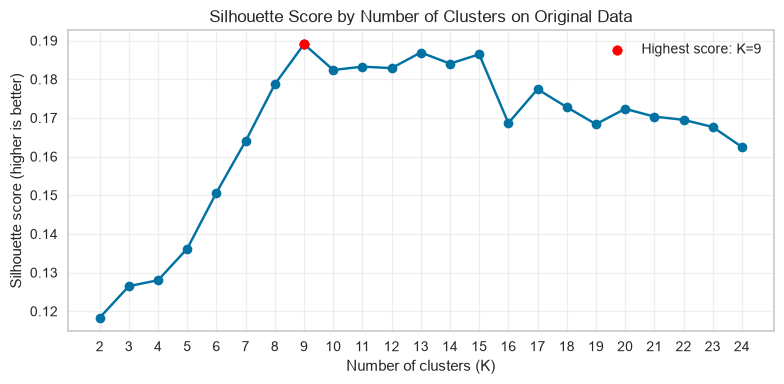

Silhouette estimate: K=9


In [46]:
# Calculate Silhouette scores for K = 2 through K = 16 on the original data.
silhouette_k_values = np.arange(2, 25)
silhouette_scores = []

for k in silhouette_k_values:
    kmeans_model = KMeans(n_clusters=int(k), random_state=42, n_init=10)
    cluster_labels = kmeans_model.fit_predict(X)
    score = silhouette_score(X, cluster_labels)
    silhouette_scores.append(score)
    print(f"K={k:2d}: silhouette score = {score:.4f}")

best_silhouette_k = int(silhouette_k_values[np.argmax(silhouette_scores)])
best_silhouette_score = float(np.max(silhouette_scores))
print(f"Highest silhouette score: {best_silhouette_score:.4f} at K={best_silhouette_k}")

plt.figure(figsize=(8, 4))
plt.plot(silhouette_k_values, silhouette_scores, marker="o")
plt.scatter(best_silhouette_k, best_silhouette_score, color="red", zorder=3, label=f"Highest score: K={best_silhouette_k}")
plt.xticks(silhouette_k_values)
plt.title("Silhouette Score by Number of Clusters on Original Data")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette score (higher is better)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Silhouette estimate: K={best_silhouette_k}")

The Silhouette score was highest at \(K=9\) across all three tested ranges: K=2–17, K=2–30, and K=2–40. However, for this experiment, I will use \(K=10\) because the dataset contains ten digit classes (0–9). This shows that we cannot always rely solely on the Elbow method or the Silhouette score to select the number of clusters. Domain knowledge is also important in such cases. Since this is a learning exercise, I will use my domain knowledge to select \(K=10\) and run the baseline K-means experiment with this value.

## K-Means on the Original Data (K=10)

Fit the baseline K-Means model to the original feature matrix `X` using K=10. The true labels `y` are not used to fit the clusters. The cell reports the model inertia and the number of samples assigned to each cluster.

In [76]:
# Fit K-Means with K=10 on the original 64-feature data.
kmeans_original = KMeans(n_clusters=10, random_state=42, n_init=10)
cluster_labels_original = kmeans_original.fit_predict(X)

cluster_sizes_original = np.bincount(cluster_labels_original, minlength=10)
print(f"Inertia: {kmeans_original.inertia_:.2f}")
print(f"Number of samples assigned: {cluster_labels_original.size}")
print("Samples in each cluster:")
for cluster_id, size in enumerate(cluster_sizes_original):
    print(f"  Cluster {cluster_id}: {size}")

Inertia: 1165256.30
Number of samples assigned: 1797
Samples in each cluster:
  Cluster 0: 176
  Cluster 1: 179
  Cluster 2: 89
  Cluster 3: 226
  Cluster 4: 198
  Cluster 5: 182
  Cluster 6: 181
  Cluster 7: 157
  Cluster 8: 241
  Cluster 9: 168


### K-Means on PCA-Reduced Data (K=10)

PCA reduces the original 64 features to the first two principal components. K-Means is then fitted to this 2D PCA representation.

PCA representation shape: (1797, 2)
Variance retained by the two components: 28.5%
K-Means inertia in PCA space: 56255.97
Samples in each PCA-space cluster:
  Cluster 0: 210
  Cluster 1: 116
  Cluster 2: 184
  Cluster 3: 170
  Cluster 4: 182
  Cluster 5: 147
  Cluster 6: 169
  Cluster 7: 218
  Cluster 8: 223
  Cluster 9: 178


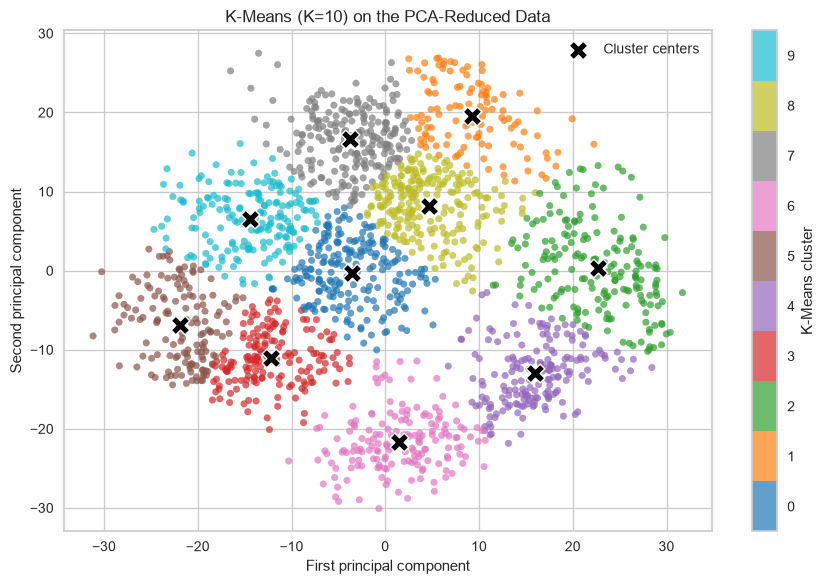

In [77]:
# Reduce the data to two principal components, then fit K-Means in that PCA space.
pca_model_2d = PCA(n_components=2)
X_pca_2d = pca_model_2d.fit_transform(X)

kmeans_pca = KMeans(n_clusters=10, random_state=42, n_init=10)
cluster_labels_pca = kmeans_pca.fit_predict(X_pca_2d)
cluster_sizes_pca = np.bincount(cluster_labels_pca, minlength=10)

print(f"PCA representation shape: {X_pca_2d.shape}")
print(f"Variance retained by the two components: {pca_model_2d.explained_variance_ratio_.sum():.1%}")
print(f"K-Means inertia in PCA space: {kmeans_pca.inertia_:.2f}")
print("Samples in each PCA-space cluster:")
for cluster_id, size in enumerate(cluster_sizes_pca):
    print(f"  Cluster {cluster_id}: {size}")

# Plot the assignments and centroids learned in PCA space.
fig, ax = plt.subplots(figsize=(9, 6))
cluster_plot = ax.scatter(
    X_pca_2d[:, 0],
    X_pca_2d[:, 1],
    c=cluster_labels_pca,
    cmap="tab10",
    vmin=-0.5,
    vmax=9.5,
    s=22,
    alpha=0.7,
)
ax.scatter(
    kmeans_pca.cluster_centers_[:, 0],
    kmeans_pca.cluster_centers_[:, 1],
    marker="X",
    s=180,
    c="black",
    edgecolors="white",
    linewidths=1,
    label="Cluster centers",
)
colorbar = fig.colorbar(cluster_plot, ax=ax, ticks=np.arange(10))
colorbar.set_label("K-Means cluster")
ax.set_title("K-Means (K=10) on the PCA-Reduced Data")
ax.set_xlabel("First principal component")
ax.set_ylabel("Second principal component")
ax.legend(loc="best")
fig.tight_layout()
plt.show()

This experiment learns the K-Means clusters from the two PCA components, unlike the baseline, which learns clusters from all 64 original features. The 2D PCA representation retains only the variance reported above, so the resulting assignments can differ from the original-data baseline.

## K-Means on the t-SNE Embedding (K=10)

t-SNE reduces the original feature matrix to two dimensions; it does not take a cluster count. Here, K-Means with K=10 is fitted to the resulting t-SNE coordinates. The true digit labels `y` are not used for either fit. The plot shows the K-Means assignments and centers in the embedding. Because t-SNE is designed to preserve local neighborhoods and can distort global distances, clustering in this embedding is a separate experiment from clustering the original data.

t-SNE embedding shape: (1797, 2)
K-Means inertia in t-SNE space: 93827.27
Samples in each t-SNE cluster:
  Cluster 0: 144
  Cluster 1: 178
  Cluster 2: 194
  Cluster 3: 193
  Cluster 4: 181
  Cluster 5: 178
  Cluster 6: 184
  Cluster 7: 194
  Cluster 8: 181
  Cluster 9: 170


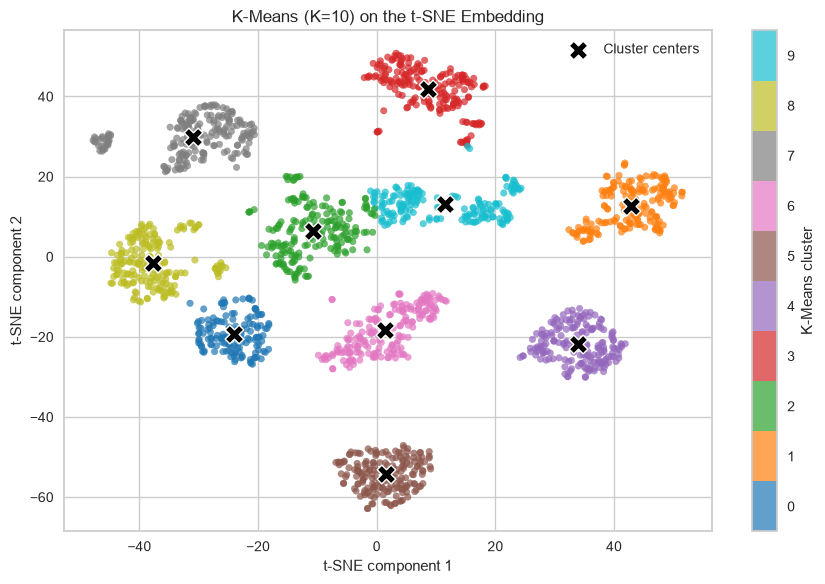

In [78]:
# Reduce the original features to two dimensions with t-SNE.
tsne_model = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    max_iter=1000,
    random_state=42,
)
X_tsne = tsne_model.fit_transform(X)

# Cluster the t-SNE coordinates into ten groups.
kmeans_tsne = KMeans(n_clusters=10, random_state=42, n_init=10)
cluster_labels_tsne = kmeans_tsne.fit_predict(X_tsne)
cluster_sizes_tsne = np.bincount(cluster_labels_tsne, minlength=10)

print(f"t-SNE embedding shape: {X_tsne.shape}")
print(f"K-Means inertia in t-SNE space: {kmeans_tsne.inertia_:.2f}")
print("Samples in each t-SNE cluster:")
for cluster_id, size in enumerate(cluster_sizes_tsne):
    print(f"  Cluster {cluster_id}: {size}")

# Plot the t-SNE coordinates colored by their K-Means assignments.
fig, ax = plt.subplots(figsize=(9, 6))
cluster_plot = ax.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=cluster_labels_tsne,
    cmap="tab10",
    vmin=-0.5,
    vmax=9.5,
    s=22,
    alpha=0.7,
)
ax.scatter(
    kmeans_tsne.cluster_centers_[:, 0],
    kmeans_tsne.cluster_centers_[:, 1],
    marker="X",
    s=180,
    c="black",
    edgecolors="white",
    linewidths=1,
    label="Cluster centers",
)
colorbar = fig.colorbar(cluster_plot, ax=ax, ticks=np.arange(10))
colorbar.set_label("K-Means cluster")
ax.set_title("K-Means (K=10) on the t-SNE Embedding")
ax.set_xlabel("t-SNE component 1")
ax.set_ylabel("t-SNE component 2")
ax.legend(loc="best")
fig.tight_layout()
plt.show()

## Validate Clustering Results with Adjusted Rand Index (ARI)

ARI compares the cluster assignments with the known digit labels `y`, which were not used to fit K-Means. It is invariant to arbitrary cluster ID numbering. A score of 1 indicates perfect agreement; a score near 0 indicates agreement similar to chance, and a negative score indicates less agreement than expected by chance. Higher scores indicate closer agreement with the digit labels, though they do not prove that one representation is best for every purpose.

Original data: ARI = 0.6669
PCA + K-Means: ARI = 0.3880
t-SNE + K-Means: ARI = 0.8891


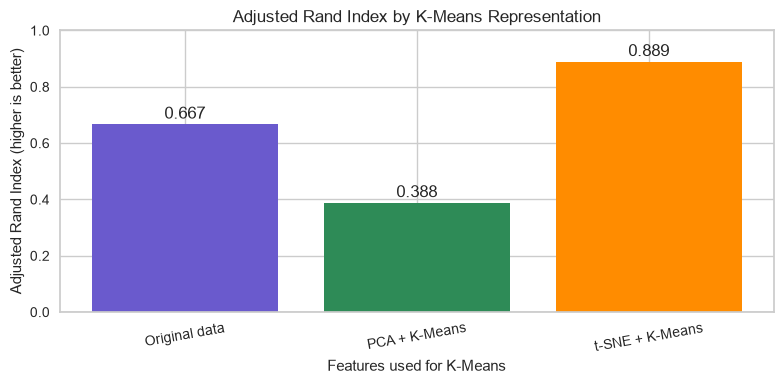

In [79]:
# Use the known digit labels only to evaluate the three unsupervised clusterings.
ari_results = {
    "Original data": adjusted_rand_score(y, cluster_labels_original),
    "PCA + K-Means": adjusted_rand_score(y, cluster_labels_pca),
    "t-SNE + K-Means": adjusted_rand_score(y, cluster_labels_tsne),
}

for method, score in ari_results.items():
    print(f"{method}: ARI = {score:.4f}")

plt.figure(figsize=(8, 4))
bars = plt.bar(ari_results.keys(), ari_results.values(), color=["slateblue", "seagreen", "darkorange"])
plt.axhline(0, color="black", linewidth=0.8)
plt.ylim(min(0, min(ari_results.values()) - 0.05), 1.0)
plt.title("Adjusted Rand Index by K-Means Representation")
plt.ylabel("Adjusted Rand Index (higher is better)")
plt.xlabel("Features used for K-Means")
plt.xticks(rotation=10)
for bar, score in zip(bars, ari_results.values()):
    plt.text(bar.get_x() + bar.get_width() / 2, score + 0.02, f"{score:.3f}", ha="center")
plt.tight_layout()
plt.show()

## Effect of t-SNE Perplexity on K-Means Clustering

Run t-SNE on the original feature matrix using perplexities 5, 15, 30, and 50. For each embedding, fit K-Means with K=10 and plot the resulting clusters. The ARI is calculated afterward against the true labels `y` for evaluation only.

Perplexity  5: ARI = 0.8283
Perplexity 15: ARI = 0.9007
Perplexity 30: ARI = 0.8891
Perplexity 50: ARI = 0.8779


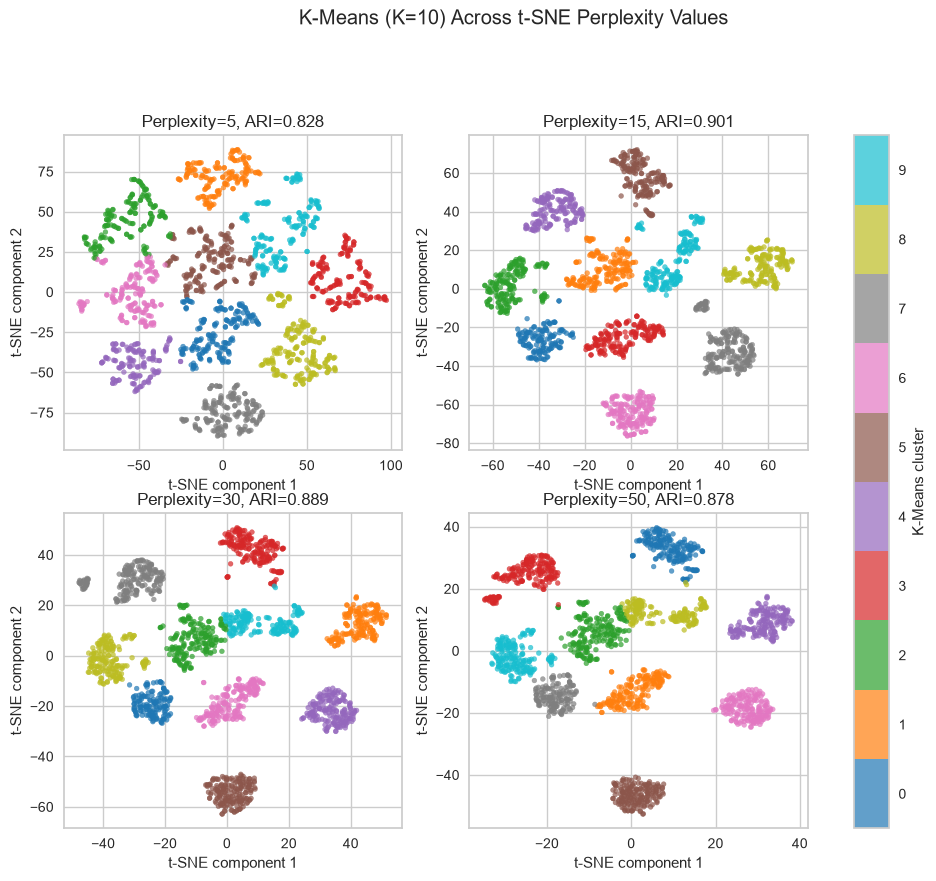

Highest ARI of 0.9007 occurs at perplexity 15.


In [80]:
perplexity_values = [5, 15, 30, 50]
tsne_embeddings_by_perplexity = {}
kmeans_labels_by_perplexity = {}
ari_by_perplexity = {}

for perplexity in perplexity_values:
    tsne_model = TSNE(
        n_components=2,
        perplexity=perplexity,
        init="pca",
        learning_rate="auto",
        max_iter=1000,
        random_state=42,
    )
    embedding = tsne_model.fit_transform(X)
    cluster_labels = KMeans(n_clusters=10, random_state=42, n_init=10).fit_predict(embedding)

    tsne_embeddings_by_perplexity[perplexity] = embedding
    kmeans_labels_by_perplexity[perplexity] = cluster_labels
    ari_by_perplexity[perplexity] = adjusted_rand_score(y, cluster_labels)
    print(f"Perplexity {perplexity:2d}: ARI = {ari_by_perplexity[perplexity]:.4f}")

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, perplexity in zip(axes.flat, perplexity_values):
    embedding = tsne_embeddings_by_perplexity[perplexity]
    cluster_labels = kmeans_labels_by_perplexity[perplexity]
    cluster_plot = ax.scatter(
        embedding[:, 0],
        embedding[:, 1],
        c=cluster_labels,
        cmap="tab10",
        vmin=-0.5,
        vmax=9.5,
        s=12,
        alpha=0.7,
    )
    ax.set_title(f"Perplexity={perplexity}, ARI={ari_by_perplexity[perplexity]:.3f}")
    ax.set_xlabel("t-SNE component 1")
    ax.set_ylabel("t-SNE component 2")

colorbar = fig.colorbar(cluster_plot, ax=list(axes.flat), ticks=np.arange(10))
colorbar.set_label("K-Means cluster")
fig.suptitle("K-Means (K=10) Across t-SNE Perplexity Values", y=1.02)
plt.show()
for perplexity in perplexity_values:
    #print highest ARI with corresponding perplexity value
    if ari_by_perplexity[perplexity] == max(ari_by_perplexity.values()):
        print(f"Highest ARI of {ari_by_perplexity[perplexity]:.4f} occurs at perplexity {perplexity}.")     

## Final ARI Comparison and Conclusion

Among the tested configurations, t-SNE with perplexity 15 achieved the highest ARI, followed by the original-data K-Means baseline; PCA achieved the lowest ARI. ARI measures agreement between cluster assignments and the true digit labels, not classification accuracy. The t-SNE score depends on settings such as perplexity, initialization, and random state, while the PCA result depends on how many components are retained.

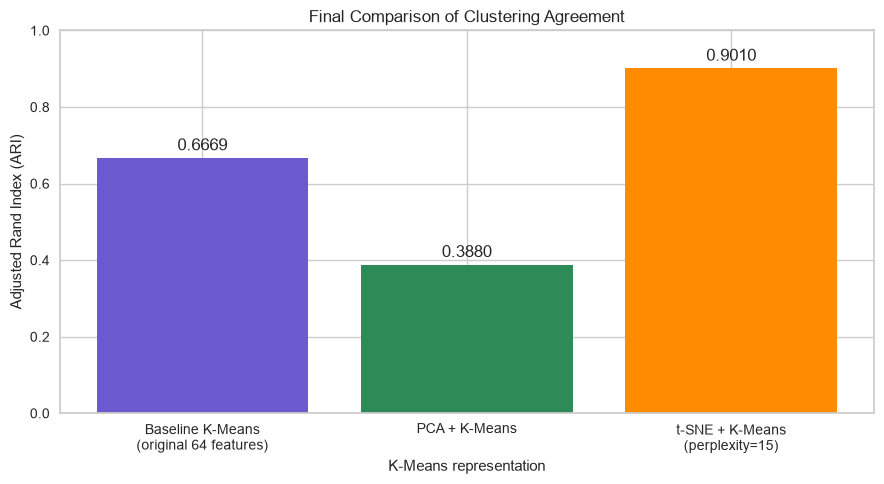

In [81]:
# Final comparison using the existing ARI results; no models are fitted in this cell.
final_ari_results = {
    "Baseline K-Means\n(original 64 features)": 0.6669,
    "PCA + K-Means": 0.3880,
    "t-SNE + K-Means\n(perplexity=15)": 0.9010,
}

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(
    final_ari_results.keys(),
    final_ari_results.values(),
    color=["slateblue", "seagreen", "darkorange"],
)
ax.set_title("Final Comparison of Clustering Agreement")
ax.set_ylabel("Adjusted Rand Index (ARI)")
ax.set_xlabel("K-Means representation")
ax.set_ylim(0, 1.0)
ax.bar_label(bars, fmt="%.4f", padding=3)
fig.tight_layout()
plt.show()